# 03a · SVM con kernel polinómico
**Responsable:** Alejandro Flores

La lógica del modelo está en `src/models/svm_polinomico.py` → función `construir_clasificador()`.
Este notebook solo entrena, evalúa, analiza y exporta usando el flujo común
(misma partición, mismo preprocesamiento y mismas métricas que los otros modelos).

El kernel polinómico calcula $K(x, x') = (\gamma \, x \cdot x' + r)^d$ con grado $d = 3$ y $r$ = `coef0` = 1.
Equivale a trabajar en un espacio con todas las combinaciones de hasta 3 variables (p. ej. `url_len` × `digit_ratio` × `is_https`)
sin calcularlas explícitamente (*kernel trick*). Con `coef0 = 1` se incluyen también los términos de grado 1 y 2.

In [1]:
# Configuración: permite importar el código común de src/ desde la carpeta notebooks/
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
plt.style.use("ggplot")
sns.set_palette("muted")

from src import config, data, evaluation
from src.training import entrenar_y_evaluar, exportar_final

CLAVE = "svm_poly"
import time

## 1. Datos

In [2]:
df = data.cargar_dataset()
print(df.shape)

(115231, 26)


## 2. Entrenamiento (80%) y evaluación (20%)

In [3]:
inicio = time.time()
pipeline, metricas, (X_test, y_test) = entrenar_y_evaluar(CLAVE, df)
print(f"Tiempo de entrenamiento y evaluación: {time.time() - inicio:.0f} s")
pipeline

Tiempo de entrenamiento y evaluación: 307 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['url_len','dom_len','tld_len',...,'digit_ratio','spec_ratio','entropy']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [4]:
print(metricas["reporte"])
print({k: round(metricas[k], 4) for k in ("accuracy", "precision", "recall", "f1", "auc")})

              precision    recall  f1-score   support

 Benigna (0)       0.98      0.99      0.98     19729
Phishing (1)       0.94      0.86      0.90      3318

    accuracy                           0.97     23047
   macro avg       0.96      0.93      0.94     23047
weighted avg       0.97      0.97      0.97     23047

{'accuracy': 0.9722, 'precision': 0.9402, 'recall': 0.8617, 'f1': 0.8992, 'auc': 0.9897}


## 3. Matriz de confusión

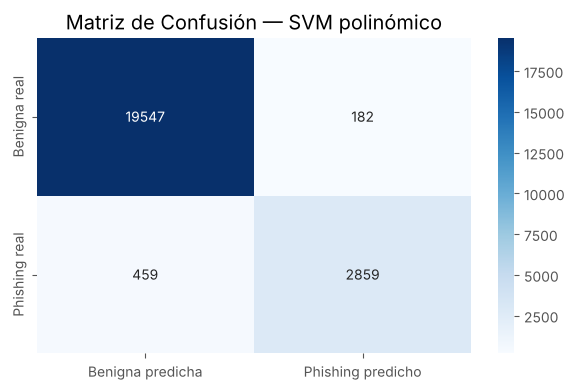

In [5]:
evaluation.graficar_matriz_confusion(metricas, f"Matriz de Confusión — {metricas['modelo']}")
plt.show()

**Interpretación** (conjunto de prueba: 23.047 URLs, 3.318 de phishing):

- **Verdaderos positivos (TP = 2.859):** phishing detectado. **Recall = 86,2 %**: de cada 100 ataques, detecta 86.
- **Falsos negativos (FN = 459):** phishing que se escapó, el error más costoso porque el usuario confiaría en el enlace.
  Son muchos menos que en el SVM lineal (803), pero más que en el gaussiano (322).
- **Falsos positivos (FP = 182):** URLs legítimas marcadas como phishing. Es la **menor cantidad de falsas alarmas de los
  cuatro modelos**: **Precision = 94,0 %**, es decir, 94 de cada 100 alertas son ataques reales.
- **Verdaderos negativos (TN = 19.547):** URLs legítimas reconocidas como tales.

## 4. Curva ROC

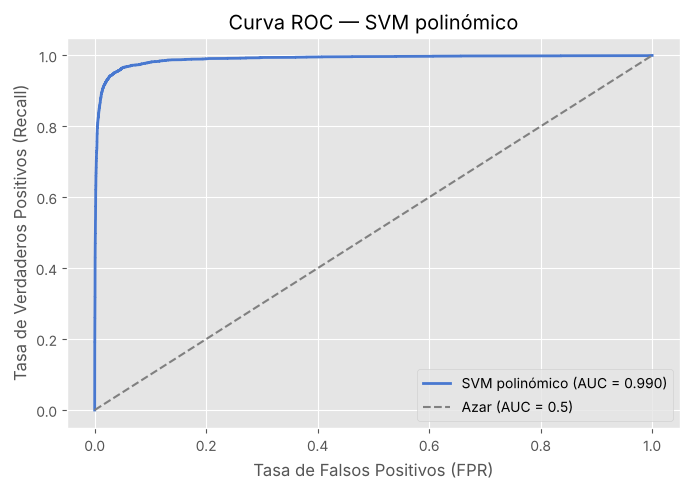

In [6]:
evaluation.graficar_roc({metricas["modelo"]: pipeline}, X_test, y_test, f"Curva ROC — {metricas['modelo']}")
plt.show()

## 5. Análisis del modelo: vectores de soporte y probabilidades

,Vectores de soporte,% del entrenamiento
Benigna (0),9250,10.0
Phishing (1),1688,1.8
Total,10938,11.9


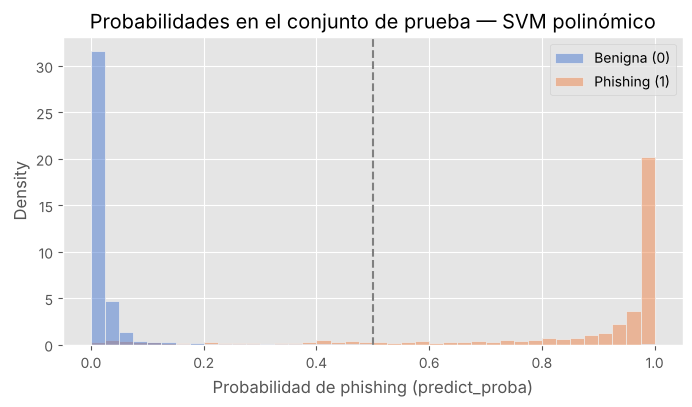

In [7]:
modelo = pipeline.named_steps["modelo"]
n_train = int(len(df) * (1 - config.TEST_SIZE))
vs = pd.DataFrame({"Vectores de soporte": modelo.n_support_},
                  index=["Benigna (0)", "Phishing (1)"])
vs.loc["Total"] = vs.sum()
vs["% del entrenamiento"] = (vs["Vectores de soporte"] / n_train * 100).round(1)
display(vs)

# Distribución de la probabilidad de phishing que asigna el modelo, por clase real
proba = pipeline.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=proba, hue=y_test.map({0: "Benigna (0)", 1: "Phishing (1)"}).values, bins=40,
             stat="density", common_norm=False, ax=ax)
ax.axvline(config.UMBRAL_PHISHING, ls="--", color="gray")
ax.set_xlabel("Probabilidad de phishing (predict_proba)")
ax.set_title(f"Probabilidades en el conjunto de prueba — {metricas['modelo']}")
plt.show()

**Interpretación:**

- El modelo usa **10.938 vectores de soporte** (11,9 % del entrenamiento): son las URLs cercanas a la frontera que la
  definen. Las demás no influyen en la predicción. 1.688 de ellos son phishing, de 13.272 URLs de phishing en entrenamiento.
- El histograma muestra que el modelo está **muy seguro** en la mayoría de casos: casi todas las benignas reciben
  probabilidad cercana a 0 y casi todo el phishing cercana a 1. Los errores se concentran en la zona intermedia.
- Frente al SVM lineal (mismo `C = 1`), el kernel polinómico sube el F1 de 0,827 a 0,899 y el AUC de 0,976 a 0,990:
  las **interacciones entre variables** (p. ej. HTTPS combinado con alta entropía y muchos dígitos) aportan información que
  un hiperplano en el espacio original no puede usar.

## 6. Exportación (reentrenado con el 100% de los datos)

In [8]:
ruta = exportar_final(CLAVE, df)
print("Modelo exportado en:", ruta)

Modelo exportado en: models/modelo_svm_poly.pkl


## 7. Conclusiones

- El SVM polinómico (grado 3, `coef0 = 1`) alcanza **F1 = 0,899**, **AUC = 0,990** y Accuracy = 97,2 %.
- Es el modelo **más preciso**: solo 182 falsas alarmas en la prueba (Precision 94,0 %), ideal si se quiere molestar lo
  menos posible al usuario.
- Su punto débil es el Recall (86,2 %): deja pasar 459 ataques, más que el SVM gaussiano.
- Costo computacional: ≈ 5 minutos para entrenar y evaluar con 92.184 URLs (incluye el escalado de Platt para obtener
  probabilidades), mucho más que los modelos lineales. El `.pkl` pesa ≈ 0,4 MB.